# Experiment: Reproducing "Deep Residual Learning for Image Recognition" (He et al., 2015)

This notebook illustrates the key concepts and aims to reproduce the key results of the paper "Deep Residual Learning for Image Recognition" published in 2015. The paper introduced the concept of "residual learning" (explained below) and demonstrated that it significantly improved the training of very deep neural networks. Residual blocks remain a fundamental building block in modern deep learning architectures as of 2026.

## 1. Introduction and Paper Summary
The key ideas of the paper are:

1. For very deep plain networks, **training error** increases with network depth. This is not due to overfitting, since the **training error** itself increases. The paper shows constructively that for a shallow network $N_{s}$ implementing some function $N(x, \theta)$, there exists a corresponding deeper network $N_{d}$ implementing the same function. Therefore, the authors hypothesise that the performance degradation is caused by optimisers being unable to find equally good parameters for a deeper network within feasible training time.
2. The authors hypothesise that in a deep network, in particular in the context of visual data, the optimal function to be learned by a sequential stack of layers may be close to the identity function. Let the optimal function to be learned by a stack of layers be some $H(x)$, where $H(x) \approx x$. The authors hypothesise that it is easier for the optimiser to learn the residual function $F(x) = H(x) - x$ than to learn $H(x)$ directly, since $F(x)$ is a relatively small perturbation from the identity function. Therefore, the output of the stack of layers can be expressed as $H(x) = F(x) + x$ where $x$ is provided "as is" by a skip connection when dimensions match, and only the residual function $F(x)$ is learned by the stack of layers. The block implementing $H(x) = F(x) + x$ is called a **residual block**, and is the key architectural innovation of the paper.
3. A central experimental result of the paper is a comparison of the performance of 20-layer and 56-layer residual networks with 20-layer and 56-layer plain networks on the CIFAR-10 dataset. The authors show that the 56-layer plain network has higher training error than the 20-layer plain network, while the 56-layer residual network achieves better performance than the 20-layer residual network.

In this notebook, we replicate the CIFAR-10 experiment mentioned above. We avoid any of the ImageNet experiments since we'll be training on a single RTX 4070 Super GPU, and training on ImageNet might take several days. We also avoid the 110-layer residual network since it is not necessary to demonstrate the key ideas of the paper.

In [1]:
# ruff: noqa: D101, D102, D103, D107
import random
import time
from collections.abc import Callable
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import wandb
from torchvision.transforms import v2 as vt
from tqdm.auto import tqdm

C:\Users\Marcello\Projects\paper-implementations\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. CIFAR-10 Dataset
We use `torchvision` to download the CIFAR-10 dataset, and `torchvision.transforms` to apply the same data preprocessing as in the original paper.

In [2]:
# download the datasets
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)

# Class list, helpful later
CLASSES = ["plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

In [3]:
# Paper states: "per-pixel mean is subtracted from each pixel", which is quite vague;
# we interpret this as a per-pixel, per-channel mean calculated over the training set.

# Note: train_dataset.data is the raw CIFAR-10 dataset in [0, 255], shape (50000, 32, 32, 3)
# which is why we need to permute and divide
mean_image = torch.mean(torch.from_numpy(train_dataset.data).permute(0, 3, 1, 2).to(torch.float32).div(255), dim=0)

print(mean_image.shape)

torch.Size([3, 32, 32])


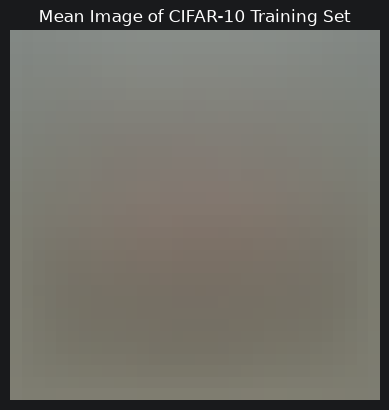

In [4]:
# sanity check: make sure all values are in [0,1]
assert mean_image.min() >= 0, "Mean image has values less than 0"
assert mean_image.max() <= 1, "Mean image has values greater than 1"

# sanity check: view the mean image
plt.imshow(mean_image.permute(1, 2, 0))
plt.axis("off")
plt.title("Mean Image of CIFAR-10 Training Set")
plt.show()

In [5]:
class SubtractMeanImage(nn.Module):
    def __init__(self, mean: torch.Tensor):
        super().__init__()
        self.register_buffer("mean", mean)

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        return image - self.mean


subtract_mean_image = SubtractMeanImage(mean_image)

# Paper, page 7: 32x32 images with per-pixel means subtracted; a 32x32 random crop
# with padding=4 is applied either to the image or its horizontal flip; transformations
# are therefore ordered as below
transform_train = vt.Compose(
    [
        vt.ToImage(),
        vt.ToDtype(torch.float32, scale=True),
        subtract_mean_image,
        vt.RandomHorizontalFlip(),
        vt.RandomCrop(32, padding=4),
    ]
)

# For the test data, flipping/cropping augmentations are not applied
transform_test = vt.Compose([vt.ToImage(), vt.ToDtype(torch.float32, scale=True), subtract_mean_image])

# redefine the datasets with the full transforms applied
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=False, transform=transform_train)
train_evaluation_dataset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=False, transform=transform_test
)
test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=False, transform=transform_test)

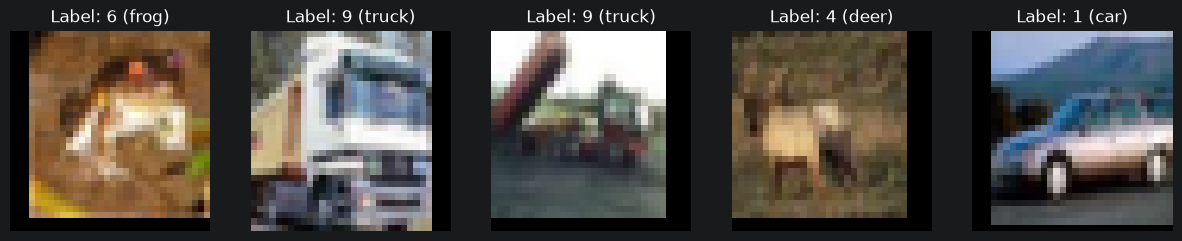

In [6]:
# sanity check: view a few training images with augmentation applied, but without
# mean subtraction so that they remain directly displayable in [0, 1]
transform_display = vt.Compose(
    [
        vt.ToImage(),
        vt.ToDtype(torch.float32, scale=True),
        vt.RandomHorizontalFlip(),
        vt.RandomCrop(32, padding=4),
    ]
)
display_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=False, transform=transform_display)
images = [display_dataset[n] for n in range(5)]
fig, axes = plt.subplots(1, len(images), figsize=(15, 3))
for i in range(len(images)):
    image, label = images[i]
    axes[i].imshow(image.permute(1, 2, 0))
    axes[i].set_title(f"Label: {label} ({CLASSES[label]})")
    axes[i].axis("off")
plt.show()

In [7]:
BATCH_SIZE = 128
# Using worker subprocesses from a notebook is unreliable on Windows because they use spawn.
NUM_WORKERS = 0


def make_data_loaders(
    seed: int,
) -> tuple[
    torch.utils.data.DataLoader,
    torch.utils.data.DataLoader,
    torch.utils.data.DataLoader,
]:
    # A fresh generator gives every model the same initial shuffling sequence.
    generator = torch.Generator().manual_seed(seed)
    loader_options = {
        "batch_size": BATCH_SIZE,
        "num_workers": NUM_WORKERS,
        "pin_memory": torch.cuda.is_available(),
    }
    train_loader = torch.utils.data.DataLoader(train_dataset, shuffle=True, generator=generator, **loader_options)
    train_evaluation_loader = torch.utils.data.DataLoader(train_evaluation_dataset, shuffle=False, **loader_options)
    test_loader = torch.utils.data.DataLoader(test_dataset, shuffle=False, **loader_options)
    return train_loader, train_evaluation_loader, test_loader

## 3. Model Architectures
In this section we define the PlainNet-20, ResNet-20, PlainNet-56, and ResNet-56 models for training. The architecture used in the CIFAR-10 experiments is described on page 7, section 4.2 of the paper.

In [8]:
# helpful shorthand for convolution -> batch norm -> ReLU
def conv_norm_relu(in_channels: int, out_channels: int, stride: int = 1) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
    )


def initialize_conv_weights(module: nn.Module) -> None:
    if isinstance(module, nn.Conv2d):
        nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
        if module.bias is not None:
            nn.init.zeros_(module.bias)

### 3.1. PlainNet Architecture

In [9]:
class PlainNet(nn.Module):
    def __init__(self, layer_pairs_per_stack: int, *args: Any, **kwargs: Any):
        super().__init__(*args, **kwargs)
        if layer_pairs_per_stack not in [3, 9]:
            raise ValueError(f"PlainNet only supports 3x2 or 9x2 layers per stack, got {layer_pairs_per_stack}x2")

        # first layer: 3 channels -> 16 channels
        self.conv1 = conv_norm_relu(3, 16)

        # stack 1: 16 channels -> 16 channels
        self.stack_16 = nn.Sequential(*[conv_norm_relu(16, 16) for _ in range(2 * layer_pairs_per_stack)])

        # stack 2: 16 channels -> 32 channels
        self.stack_32 = nn.Sequential(
            conv_norm_relu(16, 32, stride=2),
            *[conv_norm_relu(32, 32) for _ in range(2 * layer_pairs_per_stack - 1)],
        )

        # stack 3: 32 channels -> 64 channels
        self.stack_64 = nn.Sequential(
            conv_norm_relu(32, 64, stride=2),
            *[conv_norm_relu(64, 64) for _ in range(2 * layer_pairs_per_stack - 1)],
        )

        # output layer
        self.fc = nn.Linear(64, 10)

        self.apply(initialize_conv_weights)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv1(x)
        x = self.stack_16(x)
        x = self.stack_32(x)
        x = self.stack_64(x)
        x = F.avg_pool2d(x, kernel_size=8)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

### 3.2. ResNet Architecture

In [10]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, downsample: bool = False, *args: Any, **kwargs: Any):
        super().__init__(*args, **kwargs)
        self.downsample = downsample
        self.out_channels = out_channels
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, stride=2 if downsample else 1, padding=1, bias=False
        )
        self.batch_norm1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.batch_norm2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        shortcut = x
        if self.downsample:
            # downsample along spatial dimensions
            shortcut = shortcut[:, :, ::2, ::2]
            # check how many extra channels shortcut needs
            channels_to_add = self.out_channels - shortcut.shape[1]
            # half the new channels before the existing ones, half after
            channels_before = channels_to_add // 2
            channels_after = channels_to_add - channels_before
            # no before/after padding on width and height, only on channels
            shortcut = F.pad(shortcut, (0, 0, 0, 0, channels_before, channels_after))

        residual = self.relu(self.batch_norm1(self.conv1(x)))
        residual = self.batch_norm2(self.conv2(residual))
        return self.relu(residual + shortcut)

In [11]:
class ResNet(nn.Module):
    def __init__(self, layer_pairs_per_stack: int, *args: Any, **kwargs: Any):
        super().__init__(*args, **kwargs)
        if layer_pairs_per_stack not in [3, 9]:
            raise ValueError(f"ResNet only supports 3x2 or 9x2 layers per stack, got {layer_pairs_per_stack}x2")

        # first layer: 3 channels -> 16 channels
        self.conv1 = conv_norm_relu(3, 16, 1)

        # stack 1: 16 output channels
        self.stack_16 = nn.Sequential(*[ResidualBlock(16, 16) for _ in range(layer_pairs_per_stack)])

        # stack 2: 16 channels -> 32 channels
        self.stack_32 = nn.Sequential(
            ResidualBlock(16, 32, downsample=True), *[ResidualBlock(32, 32) for _ in range(layer_pairs_per_stack - 1)]
        )

        # stack 3: 32 channels -> 64 channels
        self.stack_64 = nn.Sequential(
            ResidualBlock(32, 64, downsample=True), *[ResidualBlock(64, 64) for _ in range(layer_pairs_per_stack - 1)]
        )

        self.fc = nn.Linear(64, 10)

        self.apply(initialize_conv_weights)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv1(x)
        x = self.stack_16(x)
        x = self.stack_32(x)
        x = self.stack_64(x)
        x = F.avg_pool2d(x, kernel_size=8)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

## 4. Training

Each network is trained as per section 4.2 of the paper: SGD with a batch size of 128, momentum of 0.9, weight decay of 0.0001, and an initial learning rate of 0.1. Training lasts for 64,000 iterations, with the learning rate divided by 10 after 32,000 and 48,000 iterations.

The models return logits. `CrossEntropyLoss` applies the required log-softmax internally, which is why softmax was not included inside the models' `forward` passes.

Each model is recorded as a separate run in the same Weights & Biases project. Before running this section on a new machine, authenticate it once with `uv run wandb login`. The project will be created automatically when the first run starts.

In [12]:
SEED = 147
TOTAL_STEPS = 64_000
LEARNING_RATE = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
LR_MILESTONES = (32_000, 48_000)
CHECKPOINT_DIRECTORY = Path("checkpoints")
WANDB_PROJECT = "resnet-cifar10-reproduction"
WANDB_GROUP = "plain-vs-residual-20-vs-56"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


MODEL_FACTORIES: dict[str, Callable[[], nn.Module]] = {
    "PlainNet-20": lambda: PlainNet(layer_pairs_per_stack=3),
    "ResNet-20": lambda: ResNet(layer_pairs_per_stack=3),
    "PlainNet-56": lambda: PlainNet(layer_pairs_per_stack=9),
    "ResNet-56": lambda: ResNet(layer_pairs_per_stack=9),
}


def train_model(
    model: nn.Module,
    train_loader: torch.utils.data.DataLoader,
    device: torch.device,
    run: wandb.Run,
    total_steps: int = TOTAL_STEPS,
    log_interval: int = 100,
) -> dict[str, list[float]]:
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=LR_MILESTONES, gamma=0.1)
    history: dict[str, list[float]] = {"step": [], "loss": [], "error": [], "learning_rate": []}

    model.train()
    data_iterator = iter(train_loader)
    interval_loss = torch.zeros((), device=device)
    interval_correct = torch.zeros((), dtype=torch.long, device=device)
    interval_examples = 0
    progress = tqdm(range(1, total_steps + 1), desc=run.name or "training", unit="step")

    for step in progress:
        try:
            images, labels = next(data_iterator)
        except StopIteration:
            data_iterator = iter(train_loader)
            images, labels = next(data_iterator)

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

        batch_size = labels.size(0)
        interval_loss += loss.detach() * batch_size
        interval_correct += (logits.argmax(dim=1) == labels).sum()
        interval_examples += batch_size

        if step % log_interval == 0 or step == total_steps:
            mean_loss = (interval_loss / interval_examples).item()
            error = 100 * (1 - interval_correct.item() / interval_examples)
            history["step"].append(step)
            history["loss"].append(mean_loss)
            history["error"].append(error)
            history["learning_rate"].append(optimizer.param_groups[0]["lr"])
            run.log(
                {
                    "iteration": step,
                    "train/loss": mean_loss,
                    "train/error": error,
                    "train/learning_rate": optimizer.param_groups[0]["lr"],
                }
            )
            progress.set_postfix(
                loss=f"{mean_loss:.4f}",
                error=f"{error:.2f}%",
                learning_rate=f"{optimizer.param_groups[0]['lr']:.4g}",
            )

            interval_loss.zero_()
            interval_correct.zero_()
            interval_examples = 0

    return history

Using device: cuda


In [13]:
CHECKPOINT_DIRECTORY.mkdir(parents=True, exist_ok=True)

for model_name, model_factory in MODEL_FACTORIES.items():
    print(f"\nTraining {model_name}")
    random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    with wandb.init(
        project=WANDB_PROJECT,
        name=model_name,
        group=WANDB_GROUP,
        config={
            "model": model_name,
            "batch_size": BATCH_SIZE,
            "total_steps": TOTAL_STEPS,
            "learning_rate": LEARNING_RATE,
            "momentum": MOMENTUM,
            "weight_decay": WEIGHT_DECAY,
            "lr_milestones": LR_MILESTONES,
            "seed": SEED,
        },
    ) as run:
        run.define_metric("iteration")
        run.define_metric("train/*", step_metric="iteration")

        train_loader, _, _ = make_data_loaders(SEED)
        model = model_factory().to(device)
        start_time = time.perf_counter()
        history = train_model(model, train_loader, device, run)
        elapsed_minutes = (time.perf_counter() - start_time) / 60

        checkpoint_path = CHECKPOINT_DIRECTORY / f"{model_name.lower()}.pt"
        torch.save(
            {
                "model_state_dict": {
                    name: parameter.detach().cpu().clone() for name, parameter in model.state_dict().items()
                },
                "history": history,
                "elapsed_minutes": elapsed_minutes,
                "wandb_run_path": run.path,
            },
            checkpoint_path,
        )
        run.summary["training_minutes"] = elapsed_minutes
        run.log_artifact(
            checkpoint_path,
            name=f"{model_name.lower()}-checkpoint",
            type="model",
        )
        print(f"finished in {elapsed_minutes:.1f} minutes; saved to {checkpoint_path}")

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


Training PlainNet-20


PlainNet-20: 100%|██████████| 64000/64000 [23:25<00:00, 45.54step/s, error=1.38%, learning_rate=0.001, loss=0.0396]


finished in 23.4 minutes; saved to checkpoints\plainnet-20.pt

Training ResNet-20


ResNet-20: 100%|██████████| 64000/64000 [24:04<00:00, 44.30step/s, error=0.70%, learning_rate=0.001, loss=0.0245]


finished in 24.1 minutes; saved to checkpoints\resnet-20.pt

Training PlainNet-56


PlainNet-56: 100%|██████████| 64000/64000 [30:48<00:00, 34.63step/s, error=6.84%, learning_rate=0.001, loss=0.2000]


finished in 30.8 minutes; saved to checkpoints\plainnet-56.pt

Training ResNet-56


ResNet-56: 100%|██████████| 64000/64000 [31:46<00:00, 33.56step/s, error=0.09%, learning_rate=0.001, loss=0.0045]


finished in 31.8 minutes; saved to checkpoints\resnet-56.pt


## 5. Evaluation
The evaluation reports loss and classification error on both the training and test sets. The training-set evaluation uses the training set without the data augmentation transformations applied during training, giving a more stable measure of optimisation error. The final metrics are also added to the corresponding Weights & Biases runs.

In [14]:
@torch.inference_mode()
def evaluate(
    model: nn.Module,
    data_loader: torch.utils.data.DataLoader,
    device: torch.device,
) -> dict[str, float]:
    criterion = nn.CrossEntropyLoss(reduction="sum")
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in data_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        total_loss += criterion(logits, labels).item()
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += labels.size(0)

    accuracy = 100 * total_correct / total_examples
    return {
        "loss": total_loss / total_examples,
        "accuracy": accuracy,
        "error": 100 - accuracy,
    }

In [15]:
_, train_evaluation_loader, test_loader = make_data_loaders(SEED)
results: dict[str, dict[str, Any]] = {}
wandb_api = wandb.Api()

for model_name, model_factory in MODEL_FACTORIES.items():
    checkpoint_path = CHECKPOINT_DIRECTORY / f"{model_name.lower()}.pt"
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model = model_factory().to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    train_metrics = evaluate(model, train_evaluation_loader, device)
    test_metrics = evaluate(model, test_loader, device)

    results[model_name] = {
        "history": checkpoint["history"],
        "elapsed_minutes": checkpoint["elapsed_minutes"],
        "train": train_metrics,
        "test": test_metrics,
    }

    wandb_run = wandb_api.run(checkpoint["wandb_run_path"])
    wandb_run.summary["evaluation/train_loss"] = train_metrics["loss"]
    wandb_run.summary["evaluation/train_error"] = train_metrics["error"]
    wandb_run.summary["evaluation/test_loss"] = test_metrics["loss"]
    wandb_run.summary["evaluation/test_error"] = test_metrics["error"]
    wandb_run.summary.update()

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [16]:
header = f"{'model':<12} {'train error':>12} {'test error':>11} {'minutes':>10}"
print(header)
print("-" * len(header))
for model_name, result in results.items():
    print(
        f"{model_name:<12} "
        f"{result['train']['error']:>11.2f}% "
        f"{result['test']['error']:>10.2f}% "
        f"{result['elapsed_minutes']:>10.1f}"
    )

model         train error  test error    minutes
------------------------------------------------
PlainNet-20         0.47%       9.56%       23.4
ResNet-20           0.32%       8.23%       24.1
PlainNet-56         5.17%      13.02%       30.8
ResNet-56           0.02%       6.76%       31.8


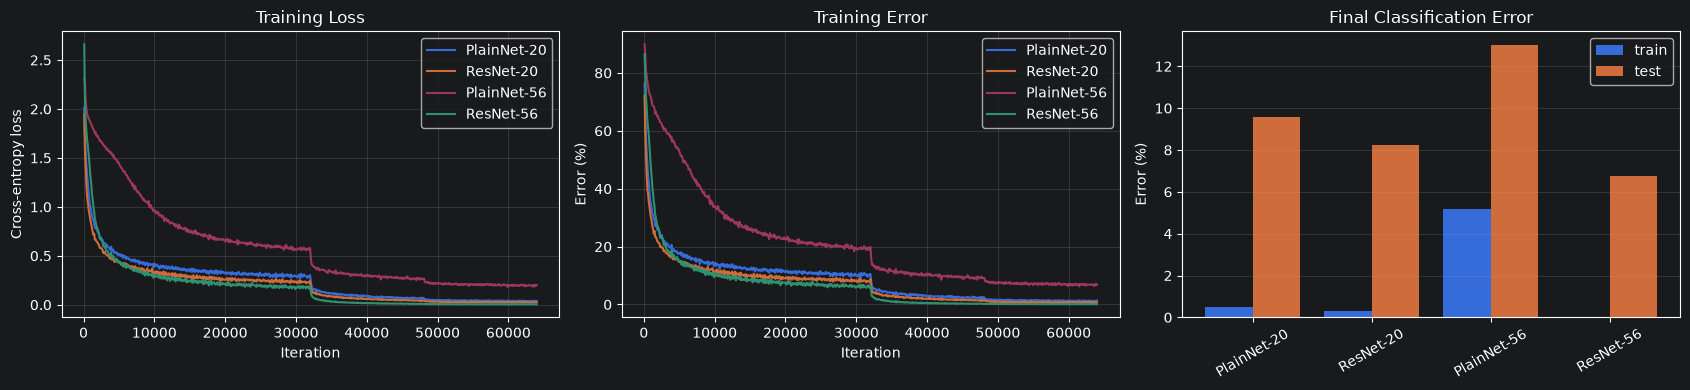

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for model_name, result in results.items():
    history = result["history"]
    axes[0].plot(history["step"], history["loss"], label=model_name)
    axes[1].plot(history["step"], history["error"], label=model_name)

axes[0].set(title="Training Loss", xlabel="Iteration", ylabel="Cross-entropy loss")
axes[1].set(title="Training Error", xlabel="Iteration", ylabel="Error (%)")
axes[0].legend()
axes[1].legend()
axes[0].grid(alpha=0.25)
axes[1].grid(alpha=0.25)

model_names = list(results)
train_errors = [results[name]["train"]["error"] for name in model_names]
test_errors = [results[name]["test"]["error"] for name in model_names]
positions = torch.arange(len(model_names)).numpy()
axes[2].bar(positions - 0.2, train_errors, width=0.4, label="train")
axes[2].bar(positions + 0.2, test_errors, width=0.4, label="test")
axes[2].set(
    title="Final Classification Error",
    ylabel="Error (%)",
    xticks=positions,
    xticklabels=model_names,
)
axes[2].tick_params(axis="x", rotation=30)
axes[2].legend()
axes[2].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Conclusion

TODO: write once results are ready